# Directional group peaks with hard integrity

Level 4. Prerequisites: convex quadratic objectives, interval constraints and the preceding matched-method lesson.

**Question:** How can a directional shared peak price change a coupled decision while preserving hard equality and physical row-unit covariance?

Prerequisite: [03-matching-published-methods](03-matching-published-methods.ipynb). Estimated reading and execution time: 25 minutes.

## Objectives

A group peak prices the largest weighted departure across several rows, rather than charging every departure independently. That choice changes the engineering question. Two temperatures sharing a comfort budget, for example, need not incur the sum of two separate penalties. This lesson uses a small authored mathematical case so that the optimum can also be derived by hand. Its purpose is to understand the actual directional implementation and compare exact formulations, without adding timing trials to either completed scientific campaign.

By the end, you can separate the hard equality from the priced box, construct reciprocal row-unit conversions, interpret formulation dimensions and identify an unsupported comparison. You will also distinguish an exact worked example from evidence of general computational improvement. The registered experiment rejected that improvement criterion; a clear derivation and successful small solve cannot reverse its result.

## Setup

Keep the notebook kernel in the existing pinned environment from `notebooks/requirements.txt`. It retains softqp0.1.0. Install the unchanged nine-distribution profile `docs/teaching/coupled/requirements.txt` into a separate external Python3.12 virtual environment, created from a direct CPython executable. Set `SOFTQP_COUPLED_PYTHON` to its absolute interpreter and `CAOS_TEMP_ROOT` to an existing external temporary directory. On Windows, Store broker launchers are refused because they cannot guarantee ownership of the complete worker tree. The bridge verifies public SDK0.2 wheel fingerprints, exact profile versions and its own source identity; it never installs dependencies during a lesson.

Each call below really executes native, compact-epigraph and directional row-split methods through `pipeline.coupled_lessons.run_comparison`. No solver is defined in these notebook cells.

```bash
python -m pip install softqp==0.1.0 numpy==2.5.4 scipy==1.18.1 matplotlib==3.11.2 osqp==1.1.3 daqp==0.10.3 elastiqp==0.2.0
```


In [1]:
# Keep path discovery and kernel version inspection in one setup step.
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.coupled_lessons import run_comparison, accepted_summary
import importlib.metadata
for distribution in ['softqp', 'numpy', 'scipy', 'matplotlib', 'osqp', 'daqp', 'elastiqp']:
    print(distribution, importlib.metadata.version(distribution))

import json
exchange_examples = {
    name: json.loads((root / f"docs/contracts/examples/softqp-coupled-{name}.json").read_text(encoding="utf-8"))
    for name in ("batch", "observation", "campaign")
}

method_names = ['Native', 'Compact epigraph', 'Directional row split']


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Data

Data source: authored two-variable input, defined by the named pipeline. Decisions x1,x2 are in metres, P=I, q=(-3,2), and the rows are x1, x2 and x1+x2. The first two have soft intervals [-1,1]m; the last has the hard equality x1+x2=0m. The objective combines a quadratic reference preference with one dimensionless directional peak. P has objective-unit/m² coefficients and q has objective-unit/m coefficients. Positive upper/lower scale coefficients have unit1/m.

The accepted-summary input is `docs/teaching/coupled/accepted-summary.json`, a byte-identical copy of independently accepted complete evidence. Reading it later inspects published inference; it does not regenerate raw-trial observations or reproduce their bootstrap. Raw reanalysis requires the separate dataset referenced in the final sources.

Owner and license: Felipe Santibáñez-Leal authored the worked-case pipeline/input (MIT); the accepted numerical summary and supporting dataset carry CC BY 4.0. The kernel and worker profiles are software dependency declarations, not observational data. Local files map to these sources:

| Input / source | Local file | Authoritative reference |
|---|---|---|
| Authored QP / MIT | `data-pipeline/pipeline/coupled_lesson_worker.py` | https://github.com/fsantibanezleal/CAOS_SoftQP |
| Accepted summary / CC BY 4.0 | `docs/teaching/coupled/accepted-summary.json` | https://doi.org/10.5281/zenodo.23875194 |
| Public SDK profile / software | `docs/teaching/coupled/requirements.txt` | https://pypi.org/project/softqp/0.2.0/ |


## Method

Write r=x−clip(x,[-1,1]²) for the soft block only. With c−=(1,1.5) and c+=(u,1), define

$$t=\max(u[r_1]_+,[r_2]_+,[-r_1]_+,1.5[-r_2]_+),\qquad
J(x)=\tfrac12\lVert x\rVert^2-3x_1+2x_2+a t+\tfrac12 b t^2.$$

The equality is imposed separately. It must not be included in an infimal-convolution identity over a fully soft box. Setting x=(s,−s) reduces the reference term to s²−5s. For s≥1, the peak is k(s−1), where k=max(u,1.5). Convexity and the reference preference exclude the opposite exterior branch. Differentiating on the positive branch gives

$$s^*=\max\left(1,\frac{5-a k+b k^2}{2+b k^2}\right).$$

This formula is an independent interpretive check for the authored case, not a replacement solver. Start with a=0.6,b=0,u=1; examine the returned decisions, original objective and equality defect before changing any parameter.

Source for the directional formulation, proximal derivation and exact lift boundaries: [native study](https://doi.org/10.5281/zenodo.23875071).

### Why a shared peak requires a group update

For a residual block $w$, positive directional scales $c_{U,i},c_{L,i}$ define a dimensionless peak $M(w)=\max_i\{c_{U,i}(w_i)_+,c_{L,i}(-w_i)_+\}$. Its price $\Psi(w)=aM(w)+bM(w)^2/2$ charges the largest scaled departure once. Replacing that maximum with a sum would change which joint decision is optimal. The [research manuscript](https://doi.org/10.5281/zenodo.23875071) derives the operation, including the need to treat hard rows separately.

Let $C$ be the soft box, $p=\Pi_C(v)$, and $r=v-p$. Because shrinking any coordinate without changing its sign cannot increase this directional maximum, the closest-box residual minimizes its penalty among residuals to points of the box. With a fixed positive diagonal metric $H=\operatorname{diag}(h_i)$, this gives

$$\operatorname{prox}^{H}_{g_C}(v)=p+\operatorname{prox}^{H}_{\Psi}(r),\qquad g_C(z)=\inf_{s\in C}\Psi(z-s).$$

To compute the residual proximal operation, choose each $c_i$ from the lower or upper scale according to the sign of $r_i$. At a trial peak $t\ge0$, the best residual coordinate is $w_i(t)=\operatorname{sign}(r_i)\min(|r_i|,t/c_i)$. Only the scalar threshold remains:

$$F(t)=at+\tfrac12bt^2+\tfrac12\sum_i h_i(|r_i|-t/c_i)_+^2.$$

On an interval with active set $S(t)=\{i:c_i|r_i|>t\}$, setting the derivative to zero gives

$$t=\frac{\sum_{i\in S(t)}h_i|r_i|/c_i-a}{b+\sum_{i\in S(t)}h_i/c_i^2}.$$

The native implementation sorts the breakpoints $c_i|r_i|$ in descending order, scans the corresponding active prefixes, and accepts only a root inside its interval. It also checks the zero endpoint. Zero prices return the original residual; an empty active set must not cause division by zero. These are reasons to call the package rather than improvise a threshold routine inside a notebook.

The proof relies on diagonal metric structure. With a dense metric, coordinate clipping can increase the quadratic distance because cross terms couple rows. Overlapping groups also invalidate independent group updates. Positive finite scales, disjoint groups and a fixed positive diagonal metric are mathematical conditions, not merely convenient defaults. No favorable two-variable example extends the theorem to dense metrics or overlapping penalties. The unchanged linear system still couples the decisions across rows.

In [2]:
# Expose actual method identities and their physical optima.
base = run_comparison(linear=0.6, quadratic=0, upper_scale=1)
base_rows = [
    f"| {name} | {record['x'][0]:.6f} | {record['x'][1]:.6f} | {record['objective']:.6f} |"
    for name, record in zip(method_names, base["records"])
]
display(Markdown("| Method | x1 (m) | x2 (m) | Objective |\n|---|---|---|---|\n" + "\n".join(base_rows)))
print('Base x1 (m)', f"{base['records'][0]['x'][0]:.6f}")


| Method | x1 (m) | x2 (m) | Objective |
|---|---|---|---|
| Native | 2.050000 | -2.050000 | -5.102500 |
| Compact epigraph | 2.050000 | -2.050000 | -5.102500 |
| Directional row split | 2.050000 | -2.050000 | -5.102500 |

Base x1 (m) 2.050000


The native update and both lifts recover approximately (2.05,−2.05)m, with objective−5.1025 in the declared objective units. A nonzero soft departure is intentional: the reference preference outweighs its marginal price until the optimum. Hard equality error remains numerical roundoff. The shared peak is dominated by the lower-side departure of the second row, whose directional scale1.5 exceeds the first upper scale1. Agreement here establishes equivalent answers for this input; it supplies neither timing evidence nor field safety certification.

Now remove the linear price and use a quadratic peak price. Its marginal cost grows with the peak. The directional row-split construction used here represents the linear shared maximum, so the quadratic cell must explicitly remain incompatible. Replacing its objective or omitting the row would manufacture apparent agreement.

In [3]:
# Retain the unsupported quadratic row-split cell rather than replacing its objective.
quadratic = run_comparison(linear=0, quadratic=1, upper_scale=1)
labels = ['Native', 'Compact epigraph', 'Directional row split']
headers = ['Method', 'State', 'x1 (m)', 'Objective']
rows = []
for name, record in zip(labels, quadratic["records"]):
    value = "-" if record["x"] is None else f"{record['x'][0]:.6f}"
    objective = "-" if record["objective"] is None else f"{record['objective']:.6f}"
    rows.append(f"| {name} | {record['state']} | {value} | {objective} |")
display(Markdown("| " + " | ".join(headers) + " |\n|---|---|---|---|\n" + "\n".join(rows)))

| Method | State | x1 (m) | Objective |
|---|---|---|---|
| Native | accepted | 1.705882 | -5.058824 |
| Compact epigraph | accepted | 1.705882 | -5.058824 |
| Directional row split | incompatible | - | - |

Changing only u to3 makes the first upper direction more expensive than the second lower direction. The common equality couples those choices: reducing x1 also changes x2. This differs from independently clipping either coordinate or replacing the maximum by a sum. Compare the new optimum with the original and with the formula above. The objective values refer to different declared policies, so their difference is not a solver accuracy gap or a performance ranking.

In [4]:
# Change one directional price while retaining the same hard equality.
directional = run_comparison(linear=0.6, quadratic=0, upper_scale=3)
directional_rows = [
    f"| {name} | {record['x'][0]:.6f} | {record['x'][1]:.6f} | {record['peak']:.6f} |"
    for name, record in zip(method_names, directional["records"])
]
display(Markdown("| Method | x1 (m) | x2 (m) | Peak (1) |\n|---|---|---|---|\n" + "\n".join(directional_rows)))


| Method | x1 (m) | x2 (m) | Peak (1) |
|---|---|---|---|
| Native | 1.600000 | -1.600000 | 1.800000 |
| Compact epigraph | 1.600000 | -1.600000 | 1.800000 |
| Directional row split | 1.600000 | -1.600000 | 1.800000 |

## Comparison

The compact epigraph introduces one shared peak variable. The row-split formulation adds directional inequality rows while retaining the original decision count. Native keeps the three original interval rows. All are exact alternatives where their assumptions hold. The next figure counts actual assembled primal variables and constraint rows on the same base input; it deliberately contains no elapsed-time axis. A smaller dimension can reduce some operations and still lose overall after projection, assembly, memory traffic or convergence effects.

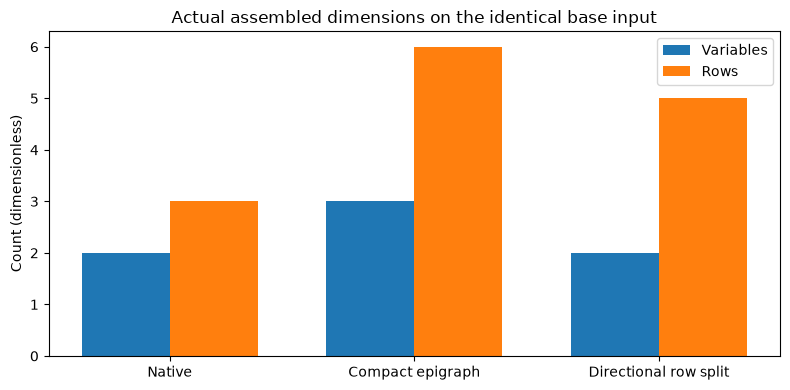

In [5]:
# Count actual assembled dimensions without turning them into a timing claim.
fig, ax = plt.subplots(figsize=(8, 4))
positions = list(range(3))
variables = [r["dimensions"]["variables"] for r in base["records"]]
constraints = [r["dimensions"]["rows"] for r in base["records"]]
ax.bar([p - 0.18 for p in positions], variables, width=0.36, label='Variables')
ax.bar([p + 0.18 for p in positions], constraints, width=0.36, label='Rows')
ax.set(xticks=positions, xticklabels=labels, ylabel='Count (dimensionless)',
       title='Actual assembled dimensions on the identical base input')
ax.legend()
fig.tight_layout()
plt.show()

The native formulation uses two primal variables and three rows; the compact epigraph uses three variables and six rows; directional row splitting uses two variables and five rows. These counts describe this exact two-variable problem, including its hard equality. They do not count every hidden workspace buffer or prove an asymptotic speed advantage. The quadratic example shows why a dimension chart also needs compatibility states: a missing mathematical representation must never appear as an especially small successful solve.

### Sensitivity of the active directional price

Sweep the linear peak price while keeping the same hard equality, Hessian and preference vector, with upper scale fixed at $u=3$. This policy differs deliberately from the base $u=1$ model; it is not another unit representation. The first upper direction dominates with $k=3$. The branch formula predicts a decreasing decision until it reaches the soft boundary. With $b=0$, that happens when $ak\ge3$, because the unconstrained derivative at $s=1$ is $-3+ak$. The three prices below sample the free preference, the predicted kink and the higher-price plateau.

Every marker is returned by a fresh call of all three actual methods. No elapsed time is recorded. Agreement between the curves concerns an original objective and equality, not a statistical timing gain. Once the optimum reaches $1$ metre, increasing the price further leaves the decision unchanged in this specific case. A flat segment is therefore an active-region effect, not evidence that the optimizer ignored its input.

The comparison also explains why "twice the price means twice the decision change" is false. The hard equality couples both coordinates and the preferred box creates a kink. Predict that mechanism before inspecting the curve; then compare the printed earlier $u=1$ and $u=3$ cases to see how directional policy changes the point where the box becomes active.


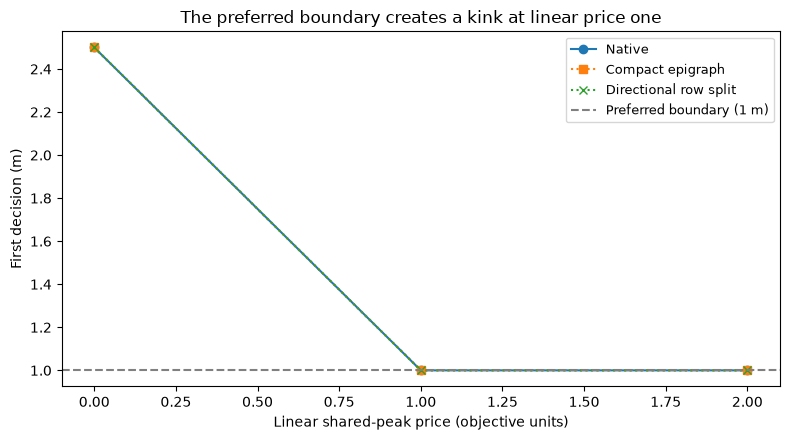

In [6]:
# Measure the free branch, predicted kink and plateau through actual methods.
prices = [0, 1, 2]
policy_sweep = [run_comparison(linear=price, quadratic=0, upper_scale=3) for price in prices]
fig, ax = plt.subplots(figsize=(8, 4.5))
for method, marker in enumerate(["o", "s", "x"]):
    decisions = [result["records"][method]["x"][0] for result in policy_sweep]
    ax.plot(prices, decisions, marker=marker, linestyle="-" if method == 0 else ":",
            label=labels[method])
ax.axhline(1, color="gray", linestyle="--", label='Preferred boundary (1 m)')
ax.set(xlabel='Linear shared-peak price (objective units)', ylabel='First decision (m)',
       title='The preferred boundary creates a kink at linear price one')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()


The computed policy sweep drops from the free preference to the preferred boundary at the predicted price, then stays on that boundary. All three actual methods share the same curve within numerical accuracy; their markers overlap because they solve equivalent formulations. The horizontal axis is a price in objective units per dimensionless peak, and the vertical axis is a physical decision in metres. This is one deterministic policy experiment, not uncertainty across plant conditions or evidence of improved runtime.


## Evidence

A row-unit change is a representation change only if every related quantity changes together. Let D=diag(d,d,1), replace A,l,u by DA,Dl,Du, and divide both directional scale vectors by d on the soft rows. Then r′=Dsoft r and each scaled directional departure is unchanged. The dimensionless peak, physical decision and original objective therefore remain invariant. The hard equality retains its original coordinate here. Run conversions d=0.01 and100 independently through the actual methods; these are fresh instructional solves, not new registered population members.

In [7]:
# Run the small reciprocal row conversion in an independent real worker.
small_rows = run_comparison(linear=0.6, quadratic=0, upper_scale=3, row_scale=0.01)
display(Markdown("| d | x1 (m) | J |\n|---|---|---|\n" +
    f"| 0.01 | {small_rows['records'][0]['x'][0]:.6f} | {small_rows['records'][0]['objective']:.6f} |"))

| d | x1 (m) | J |
|---|---|---|
| 0.01 | 1.600000 | -4.360000 |

The second conversion uses the same physical policy at the opposite scale. Compare the recovered x1 across all three actual methods; a changed decision would contradict this coordinate transformation.

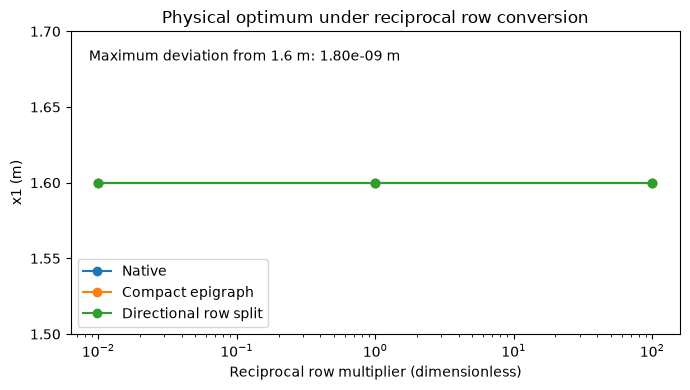

In [8]:
# Repeat at the opposite row scale to distinguish physical invariance from one successful solve.
large_rows = run_comparison(linear=0.6, quadratic=0, upper_scale=3, row_scale=100)
fig, ax = plt.subplots(figsize=(7, 4))
for i, label in enumerate(labels):
    values = [r["records"][i]["x"][0] for r in (small_rows, directional, large_rows)]
    ax.plot([0.01, 1, 100], values, marker="o", label=label)
ax.set(xscale="log", xlabel='Reciprocal row multiplier (dimensionless)',
       ylabel="x1 (m)", title='Physical optimum under reciprocal row conversion')
ax.set_ylim(1.5, 1.7)
ax.set_yticks([1.5, 1.55, 1.6, 1.65, 1.7])
maximum_error = max(abs(record["x"][0] - 1.6)
                    for result in (small_rows, directional, large_rows) for record in result["records"])
error_text = f"{maximum_error:.2e}"
ax.text(0.03, 0.94, 'Maximum deviation from 1.6 m: ' + error_text + " m", transform=ax.transAxes, va="top")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

Across both reciprocal conversions the recovered physical x1 stays at the same value as the unconverted directional policy. The horizontal axis is the positive row-coordinate multiplier, not elapsed time or a new physical decision unit. The solver may follow a different numerical path after scaling; invariance concerns the original mathematical answer within the stated accuracy checks. Omitting inverse directional scales would change the price rather than its representation. As a deliberate counterexample, increasing u again to4 changes the policy and moves the optimum; no covariance claim applies to that modification.

The common physical y-range is1.5 to1.7m, so the three method curves overlap. The annotated maximum deviation from the analytic1.6m answer quantifies backend roundoff; it does not imply a meaningful separation between these physical decisions.

In [9]:
# Alter the mathematical price deliberately as a non-covariant policy control.
changed_policy = run_comparison(linear=0.6, quadratic=0, upper_scale=4)
display(Markdown("| u | x1 (m) |\n|---|---|\n" +
    f"| 4 | {changed_policy['records'][0]['x'][0]:.6f} |"))

| u | x1 (m) |
|---|---|
| 4 | 1.300000 |

The complete registered comparison is a separate evidential question. Its accepted summary retains144 held-out instances, six seed clusters and nine prescribed failed pairs. The table below reads that exact reviewed result once. The score is a paired relative-reduction endpoint with a failure rule; it cannot be translated into a universal slowdown multiplier. Its uncertainty and retained failures belong to the conclusion, alongside the fact that the required improvement was not established. No resampling, threshold revision or selection of favorable instances occurs in this lesson.

In [10]:
# Read accepted complete inference once; this is not raw-trial reanalysis.
evidence = accepted_summary()["primary"]
head = 'Held-out cases | Seed clusters | Failed pairs | Reduction (%) | 95% interval (%)'
lower, upper = evidence["confidence_interval"]
body = (f"| {evidence['denominator']} | {evidence['seed_clusters']} | {evidence['failed_pairs']} | "
        f"{100*evidence['estimate']:.4f} | [{100*lower:.4f}, {100*upper:.4f}] |")
display(Markdown("| " + head + " |\n|---|---|---|---|---|\n" + body))

| Held-out cases | Seed clusters | Failed pairs | Reduction (%) | 95% interval (%) |
|---|---|---|---|---|
| 144 | 6 | 9 | -212.4499 | [-225.3366, -192.8738] |

### Use it on your own data

The small bridge intentionally exposes four scalar inputs, not an arbitrary QP upload. `linear` and `quadratic` range from zero to ten, `upper_scale` from 0.25 to four, and `row_scale` from 0.01 to one hundred. Its `softqp-coupled-lesson` output binds those inputs to `input_sha256`, a worker source digest, SDK version and exactly three method records. Each record retains `state`, `reason`, decision, original objective, peak, hard violation, KKT maximum and assembled dimensions. An incompatible quadratic row-split record has no invented decision. A missing runtime raises an explicit configuration error rather than substituting recorded numbers.

To adapt a general model, use the separate SDK2 `PeakProblem` and `PeakGroup` interface documented by the pipeline worker. Supply sparse `P,A`, vectors `q,lower,upper`, and disjoint row-index groups. Each group declares lower/upper scale arrays and linear/quadratic prices. Rows outside all groups remain hard. Use the exact group dimensions, preserve hard equality classification, and attach original physical units before comparing methods. The didactic bridge is deliberately not widened to accept arbitrary user models without those admission rules.

The offline batch, observation and campaign exchanges explain how such a larger study moves through the tool. `softqp-coupled-batch` carries CSC matrices (`shape,data,indices,indptr`), bounds, groups, forecast updates and a unit map. A null lower endpoint denotes negative infinity; a null upper endpoint denotes positive infinity. Null is not zero. Forecast vectors keep matrix dimensions and the finite-side pattern fixed. `softqp-coupled-observation` identifies a method or oracle, input id, seed, split, repetition and warm-up status. An accepted method observation requires all thirty-two accepted forecast frames with backend candidates and a positive elapsed scope; failures remain reasons, not silently dropped frames.

`softqp-coupled-campaign` binds the registered inventory, environment and source hashes to raw/CSV hashes, counts and paired reductions. Its primary denominator and failed-pair list are evidential fields, not tuning parameters. The three schema examples inspected below teach these shapes only: zero hashes and their explicit example reasons are not executed research. The complete scientific data lives in the linked separate dataset. These offline contracts currently have no validated browser replay adapter, so a valid example cannot be presented as deployed solver execution.

When adapting units, transform row coefficients and endpoints together and apply inverse directional scales; when adapting policy, change the price deliberately and call it a new problem. Before performance evaluation, compare the original objective, hard equality, stationarity and Fenchel consistency against an independent formulation. An apparently converged backend status cannot replace that admission step.

In your local SDK2 script, after reading a JSON batch document with the declared format, the public sequence is below. This block belongs to the separate runtime, not the SDK1 kernel of this notebook:

```python
from pipeline.coupled_contract import decode_batch
from softqp.peak import solve_peak

batch = decode_batch(document)
result = solve_peak(batch.problem, "native", alpha=1, adaptive_rho=False, scaling=0)
```

Decoding applies the schema and cross-field matrix, unit and forecast conditions. Preserve the complete original result and perform original-space admission before constructing a campaign observation; a successful call alone does not populate that contract.


In [11]:
# Expose declared exchange fields; fixture examples are not executed observations.
batch_example = exchange_examples["batch"]
observation_example = exchange_examples["observation"]
campaign_example = exchange_examples["campaign"]
print('Batch fields:', sorted(batch_example))
print('Variable / row units:',
      batch_example["units"]["variable"], batch_example["units"]["row"])
print('Observation example state:', observation_example["state"])
print('Observation reason:', observation_example["reason"])
print('Campaign example inventory:', len(campaign_example["inventory"]))
print('Live lesson schema / SDK:', base["schema_version"], base["sdk_version"])

Batch fields: ['description', 'kind', 'problem', 'schema_version', 'units', 'updates']
Variable / row units: ['dimensionless', 'dimensionless', 'dimensionless', 'dimensionless'] ['dimensionless', 'dimensionless', 'dimensionless', 'dimensionless', 'dimensionless', 'dimensionless', 'dimensionless', 'dimensionless', 'dimensionless', 'dimensionless', 'dimensionless', 'dimensionless']
Observation example state: failed
Observation reason: Schema example only; no solver run or scientific observation.
Campaign example inventory: 0
Live lesson schema / SDK: softqp.coupled-lesson/v1 0.2.0


## Results

**Answer:** A linear shared price0.6 yields x1≈2.050000m in the base case, and changing the first upper directional scale to3 yields x1≈1.6m while preserving x1+x2≈0m. Reciprocal row conversions0.01 and100 preserve that latter physical decision. These numbers come from actual method calls above. The quadratic policy remains supported by native and epigraph methods and explicitly incompatible with this row-split reference.

The scientific endpoint is negative: approximately−212.45% with a95% seed-cluster interval approximately[−225.34%,−192.87%], including nine failed pairs. It does not establish the registered10% gain. Exact agreement and reduced row count in the worked case explain representation, not a general advantage.

Limitations: the case is a convex, fixed-metric two-variable instructional model. Disjoint positive directional groups and the stated solver settings are assumed. It contains no controller certification, trained policy, measured plant, universal timing conclusion or priority proof. The process boundary and numerical acceptance checks improve reproducibility but cannot supply missing empirical value.

## Summary

The engineering decision is the priced directional maximum; the numerical representation is a second decision. A reader can now alter a or b, predict the branch optimum analytically and then ask the actual methods for a checked answer. Preserve the hard row, original units and unsupported states when adapting the example.

Exercises: first find a linear price that places the optimum exactly at the soft-box boundary and explain the marginal condition. Then change the upper scale below1.5 and explain why the lower direction still dominates. Finally attempt a row-coordinate conversion without reciprocal scales, derive its changed objective before running it, and explain why calling that result a units failure would confuse a different policy with a different representation. None of these exploratory examples revises the registered study.

## References

- Directional study, native derivation and complete negative result: https://doi.org/10.5281/zenodo.23875071
- Supporting complete registered dataset: https://doi.org/10.5281/zenodo.23875194
- Published generalized slack projection: https://arxiv.org/abs/2610.35631
- OSQP ADMM and solver assumptions: https://osqp.org/docs/solver/
- Public implementation: https://pypi.org/project/softqp/0.2.0/

The directional study establishes the stated derivations and reported experiment, not priority or superiority.